In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
FILE = "Water Quality.csv"  # Change to full path if required.

def locate_csv(filename):
    p = Path(filename)
    if p.is_file(): return p.resolve()
    for root in [Path.cwd(), Path.home()/"Desktop", Path.home()/"Downloads", Path.home()/"Documents"]:
        if root.exists():
            try:
                for item in root.rglob("*"):
                    if item.is_file() and item.name.lower() == filename.lower(): return item.resolve()
            except (OSError, PermissionError): pass
    try:
        import tkinter as tk
        from tkinter import filedialog
        w=tk.Tk(); w.withdraw(); w.attributes("-topmost", True)
        chosen=filedialog.askopenfilename(title="Select Water Quality.csv",filetypes=[("CSV","*.csv")])
        w.destroy()
        return Path(chosen) if chosen else None
    except Exception: return None

csv_path=locate_csv(FILE)
if csv_path is None: raise FileNotFoundError("Put Water Quality.csv beside the notebook or set FILE to its full path.")
df=pd.read_csv(csv_path, low_memory=False); df.columns=df.columns.str.strip()
required={"MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"}
if not required.issubset(df.columns): raise ValueError(f"Missing columns: {sorted(required-set(df.columns))}")
df["ActivityStartDate"]=pd.to_datetime(df["ActivityStartDate"], errors="coerce")
df["ResultValue"]=pd.to_numeric(df["ResultValue"], errors="coerce")
df=df.dropna(subset=["MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"]).copy()
for c in ["MonitoringLocationID","CharacteristicName"]: df[c]=df[c].astype(str).str.strip()
if "ResultUnit" not in df: df["ResultUnit"]="UNSPECIFIED"
df["ResultUnit"]=df["ResultUnit"].fillna("UNSPECIFIED").astype(str).str.strip()
print("Loaded:", csv_path, "| rows:",len(df),"| locations:",df.MonitoringLocationID.nunique(),"| parameters:",df.CharacteristicName.nunique())

Loaded: C:\Users\YASH\Desktop\water\Water Quality.csv | rows: 229916 | locations: 58 | parameters: 83


In [2]:
df["YearMonth"]=df.ActivityStartDate.dt.to_period("M")
monthly=df.groupby(["MonitoringLocationID","CharacteristicName","ResultUnit","YearMonth"])["ResultValue"].median().reset_index()
monthly["Month"]=monthly.YearMonth.dt.to_timestamp()
coverage=monthly.groupby(["MonitoringLocationID","CharacteristicName","ResultUnit"]).size().rename("Months").reset_index().sort_values("Months",ascending=False)
display(coverage.head(20))

,MonitoringLocationID,CharacteristicName,ResultUnit,Months
907,NS01ED0005,pH,UNSPECIFIED,272
887,NS01ED0005,Specific conductance,uS/cm,272
838,NS01ED0005,Aluminum,ug/L,272
871,NS01ED0005,Manganese,ug/L,271
896,NS01ED0005,"Total Nitrogen, mixed forms",mg/L,271
870,NS01ED0005,Magnesium,mg/L,271
878,NS01ED0005,Organic carbon,mg/L,271
851,NS01ED0005,Chloride,mg/L,271
886,NS01ED0005,Sodium,mg/L,271
889,NS01ED0005,Sulfate,mg/L,271


Selected: NS01ED0005 pH UNSPECIFIED n = 287


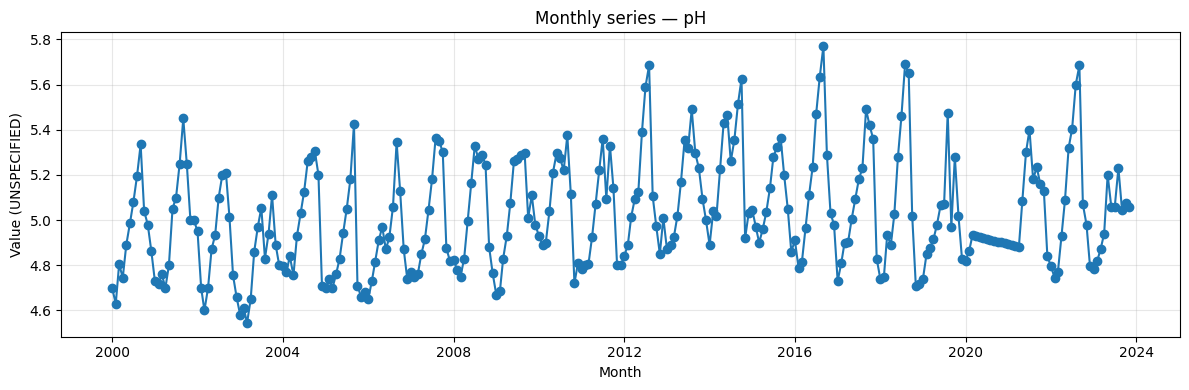

In [3]:
LOCATION_ID=None; PARAMETER=None; UNIT=None; MIN_MONTHS=24
eligible=coverage[coverage.Months>=MIN_MONTHS]
if eligible.empty: raise ValueError(f"No series has {MIN_MONTHS} monthly records.")
if LOCATION_ID is None or PARAMETER is None:
    r=eligible.iloc[0]; LOCATION_ID=str(r.MonitoringLocationID); PARAMETER=str(r.CharacteristicName)
    if UNIT is None: UNIT=str(r.ResultUnit)
elif UNIT is None:
    r=coverage[(coverage.MonitoringLocationID==LOCATION_ID)&(coverage.CharacteristicName==PARAMETER)].iloc[0]; UNIT=str(r.ResultUnit)
selected=monthly[(monthly.MonitoringLocationID==LOCATION_ID)&(monthly.CharacteristicName==PARAMETER)&(monthly.ResultUnit==UNIT)].sort_values("Month")
series=selected.set_index("Month")["ResultValue"].asfreq("MS").astype(float).interpolate(method="time",limit_area="inside").dropna()
if len(series)<MIN_MONTHS: raise ValueError("Not enough usable months for changepoint analysis.")
print("Selected:",LOCATION_ID,PARAMETER,UNIT,"n =",len(series))
plt.figure(figsize=(12,4)); plt.plot(series.index,series.values,marker="o")
plt.title(f"Monthly series — {PARAMETER}"); plt.xlabel("Month"); plt.ylabel(f"Value ({UNIT})")
plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()

In [7]:
try:
    %pip install ruptures
    import ruptures as rpt
    pelt_available=True
except ImportError:
    pelt_available=False
    print("Install PELT dependency with: python -m pip install ruptures")
pelt_idx=[]
if pelt_available:
    x=series.to_numpy(float); med=np.median(x); mad=np.median(np.abs(x-med))
    scale=1.4826*mad if mad>0 else (np.std(x) if np.std(x)>0 else 1.0)
    z=((x-med)/scale).reshape(-1,1)
    penalty=3*np.log(len(z))  # heuristic; test sensitivity
    pelt=rpt.Pelt(model="rbf",min_size=3,jump=1).fit(z)
    breaks=pelt.predict(pen=penalty)
    pelt_idx=[i for i in breaks if i<len(series)]
    print("Penalty:",round(penalty,3),"change dates:",[str(series.index[i]) for i in pelt_idx])

  Using cached ruptures-1.1.9.tar.gz (308 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Failed to build ruptures
Note: you may need to restart the kernel to use updated packages.
Install PELT dependency with: python -m pip install ruptures


  error: subprocess-exited-with-error
  
  × Building wheel for ruptures (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [105 lines of output]
      C:\Users\YASH\AppData\Local\Temp\pip-build-env-40iobblq\overlay\Lib\site-packages\setuptools_scm\_integration\deprecation.py:9: UserWarning: setup.cfg: at [metadata]
      version = attr: ... is forcing setuptools to override the version setuptools-scm did already set
      When using setuptools-scm it's invalid to use setuptools dynamic version as well, please remove it.
      Setuptools-scm is responsible for setting the version, forcing setuptools to override creates errors.
        warnings.warn(
      C:\Users\YASH\AppData\Local\Temp\pip-build-env-40iobblq\overlay\Lib\site-packages\setuptools\dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
      !!
      
              ********************************************************************************
              Please consider removing

In [8]:
x=series.to_numpy(float); med=np.median(x); mad=np.median(np.abs(x-med))
scale=1.4826*mad if mad>0 else (np.std(x) if np.std(x)>0 else 1.0)
z=(x-med)/scale
K=0.5; H=5.0  # tune and document; higher H usually reduces flags
pos=np.zeros(len(z)); neg=np.zeros(len(z)); cusum_idx=[]
for i in range(1,len(z)):
    pos[i]=max(0,pos[i-1]+z[i]-K); neg[i]=min(0,neg[i-1]+z[i]+K)
    if pos[i]>H or neg[i]<-H:
        cusum_idx.append(i); pos[i]=0; neg[i]=0
print("CUSUM K/H:",K,H,"| candidate dates:",[str(series.index[i]) for i in cusum_idx])

CUSUM K/H: 0.5 5.0 | candidate dates: ['2003-04-01 00:00:00', '2012-08-01 00:00:00', '2013-10-01 00:00:00', '2014-08-01 00:00:00', '2016-09-01 00:00:00', '2018-09-01 00:00:00', '2022-09-01 00:00:00']


In [9]:
# Educational BOCPD approximation with constant hazard and Gaussian predictive likelihood.
# Threshold/hazard are tuning settings, not universal defaults.
def bocpd_gaussian(x,hazard=1/24,max_run=120):
    x=np.asarray(x,float); n=len(x); width=min(max_run,n)+1
    center=np.median(x); mad=np.median(np.abs(x-center))
    sigma=1.4826*mad if mad>0 else (np.std(x) if np.std(x)>0 else 1.0)
    R=np.zeros((n+1,width)); R[0,0]=1.0
    means=np.zeros((n+1,width)); counts=np.zeros((n+1,width)); m2=np.zeros((n+1,width))
    cp=np.zeros(n)
    for t in range(n):
        like=np.ones(width)
        for r in range(min(t,width-1)+1):
            cnt=counts[t,r]; mu=means[t,r] if cnt else center
            var=m2[t,r]/max(cnt-1,1) if cnt>1 else sigma**2
            var=max(var,(.1*sigma)**2)
            pv=var+sigma**2/max(cnt+1,1)
            like[r]=np.exp(-.5*(x[t]-mu)**2/pv)/np.sqrt(2*np.pi*pv)
        growth=R[t]*like*(1-hazard); R[t+1]=0
        R[t+1,0]=np.sum(R[t]*like*hazard)
        upto=min(t+1,width-1); R[t+1,1:upto+1]=growth[:upto]
        total=R[t+1].sum()
        if total>0: R[t+1]/=total
        cp[t]=R[t+1,0]
        for r in range(1,upto+1):
            oldn=counts[t,r-1]; oldmu=means[t,r-1]; newn=oldn+1
            newmu=oldmu+(x[t]-oldmu)/newn
            means[t+1,r]=newmu; counts[t+1,r]=newn
            m2[t+1,r]=m2[t,r-1]+(x[t]-oldmu)*(x[t]-newmu) if oldn>0 else 0
    return cp
HAZARD=1/24; CP_THRESHOLD=.20
bocp=bocpd_gaussian(series.to_numpy(),hazard=HAZARD,max_run=min(120,len(series)))
bocpd_idx=np.where(bocp>=CP_THRESHOLD)[0].tolist()
print("Hazard:",HAZARD,"threshold:",CP_THRESHOLD,"candidate dates:",[str(series.index[i]) for i in bocpd_idx])

Hazard: 0.041666666666666664 threshold: 0.2 candidate dates: []


,Method,Date,Value,Index
0,CUSUM,2003-04-01,4.650,39
1,CUSUM,2012-08-01,5.685,151
2,CUSUM,2013-10-01,5.230,165
3,CUSUM,2014-08-01,5.355,175
4,CUSUM,2016-09-01,5.770,200
5,CUSUM,2018-09-01,5.650,224
6,CUSUM,2022-09-01,5.685,272


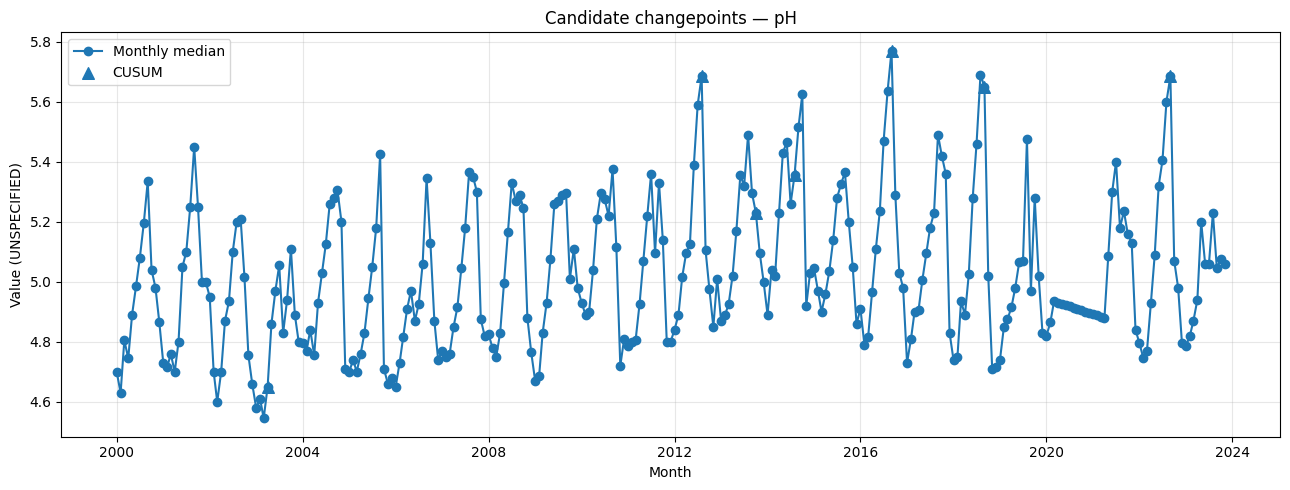

Saved outputs: C:\Users\YASH\Desktop\water\task2_changepoint_outputs


In [10]:
rows=[]
for method,idxs in [("PELT",pelt_idx),("CUSUM",cusum_idx),("BOCPD",bocpd_idx)]:
    for i in idxs:
        if 0<=i<len(series): rows.append({"Method":method,"Date":series.index[i],"Value":series.iloc[i],"Index":i})
changes=pd.DataFrame(rows,columns=["Method","Date","Value","Index"])
display(changes)
plt.figure(figsize=(13,5)); plt.plot(series.index,series.values,marker="o",label="Monthly median")
for method,idxs,marker in [("PELT",pelt_idx,"x"),("CUSUM",cusum_idx,"^"),("BOCPD",bocpd_idx,"s")]:
    ix=[i for i in idxs if 0<=i<len(series)]
    if ix: plt.scatter(series.index[ix],series.iloc[ix],marker=marker,s=70,label=method)
plt.title(f"Candidate changepoints — {PARAMETER}"); plt.xlabel("Month"); plt.ylabel(f"Value ({UNIT})")
plt.legend(); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()
outdir=csv_path.parent/"task2_changepoint_outputs"; outdir.mkdir(exist_ok=True)
changes.to_csv(outdir/"changepoint_candidates.csv",index=False)
pd.DataFrame({"Month":series.index,"Value":series.values,"BOCPD_Probability":bocp}).to_csv(outdir/"bocpd_probabilities.csv",index=False)
print("Saved outputs:",outdir)